# Week 1: Data collection, quality and exploratory analysis

This notebook uses the supplied PDF’s Python data-science workflow. Run cells in order. Model fitting and evaluation are real computations; the bundled source is clearly labelled synthetic practice data.

## Learn, practise, complete
**Topics:** Python functions, NumPy statistics, pandas groupby/dates, quality checks, visualization, trend and seasonality.

**YouTube:** [Corey Schafer Python](https://www.youtube.com/playlist?list=PL-osiE80TeTt2d9bfVyTiXJA-UTHn6WwU), [Corey Schafer pandas](https://www.youtube.com/playlist?list=PL-osiE80TeTsWmV9i9c58mdDCSskIFdDS).

**Websites:** [pandas tutorials](https://pandas.pydata.org/docs/getting_started/intro_tutorials/), [statsmodels seasonal decomposition](https://www.statsmodels.org/stable/generated/statsmodels.tsa.seasonal.seasonal_decompose.html).

**Your task:** repeat on a licensed real-data subset; record cleaning decisions and three observations supported by the training-period charts. Finish when you can recreate the data audit without editing raw input.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
assert (ROOT/'src/data.py').is_file(), 'Open this notebook from the project or notebooks folder.'
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from IPython import get_ipython
if get_ipython() is not None:
    get_ipython().run_line_magic('matplotlib','inline')
from src.data import read_sales, source_info, file_hash

# Change this to a licensed canonical sales CSV for your own analysis.
DATA_PATH = ROOT/'data/raw/demo_sales.csv'
data = read_sales(DATA_PATH)
source = source_info(DATA_PATH)
print('DATA SOURCE:', source['data_kind'])
print('SOURCE SHA-256:', source['source_sha256'])
print('Bundled data is synthetic practice data, not real retail observations.')
display(data.head())

DATA SOURCE: synthetic practice; not observed retail sales
SOURCE SHA-256: c0f8a91575ec1819cb02c4783d23f8e7d3d172d1cd83fce572aaff57302c67fc
Bundled data is synthetic practice data, not real retail observations.


,date,store,item,sales
0,2022-01-01,1,1,32
1,2022-01-02,1,1,28
2,2022-01-03,1,1,18
3,2022-01-04,1,1,11
4,2022-01-05,1,1,16


## 1. Define the input contract
One row is observed daily sales for one store–item pair. IDs are strings, dates are daily, sales are finite/nonnegative. Missing dates are not automatically zeros. The supplied dataset has no observed stock, lead time or promotion fields. Review `docs/DATA_GUIDE.md` before using Kaggle data.

In [2]:
assert not data.duplicated(['date','store','item']).any()
display(data.dtypes.to_frame('dtype').astype(str))
display(data.groupby(['store','item']).sales.agg(['count','mean','std','min','max']))
display(data.isna().sum().to_frame('missing'))

,dtype
date,datetime64[ns]
store,object
item,object
sales,int64


count       mean        std  min  max
store item                                       
1     1       730  23.723288   7.169141    6   53
      2       730  28.708219   8.388938    7   59
      3       730  33.453425   9.435865   14   68
      4       730  38.790411  10.380612    8   72
2     1       730  27.428767   7.792296    8   51
      2       730  32.463014   8.876960   13   64
      3       730  37.430137  10.206841   14   73
      4       730  42.535616  11.622289   16   81

,missing
date,0
store,0
item,0
sales,0


## 2. Reproduce the data-quality report without modifying raw bytes

In [3]:
from src.data import prepare
before = file_hash(DATA_PATH)
audit = prepare(DATA_PATH, ROOT/'reports/week01')
assert file_hash(DATA_PATH) == before
if get_ipython() is not None:
    get_ipython().run_line_magic('matplotlib','inline')
display(pd.Series(audit).to_frame('value'))
interim = ROOT/'data/interim'
interim.mkdir(parents=True,exist_ok=True)
data.to_csv(interim/'cleaned_sales.csv',index=False)

,value
data_kind,synthetic practice; not observed retail sales
seed,42
days_per_series,730
generator,Poisson counts with assumed weekday effect and...
source_sha256,c0f8a91575ec1819cb02c4783d23f8e7d3d172d1cd83fc...
source_file,demo_sales.csv
rows,5840
series,8
start,2022-01-01
end,2023-12-31


## 3. Explore training-period demand
Keep the last 56 days aside for validation/test. Audit the full source structurally, but use the earlier training partition to study patterns that may inform modeling decisions.

train_end           2023-11-05 00:00:00
validation_start    2023-11-06 00:00:00
validation_end      2023-12-03 00:00:00
test_start          2023-12-04 00:00:00
test_end            2023-12-31 00:00:00
dtype: object

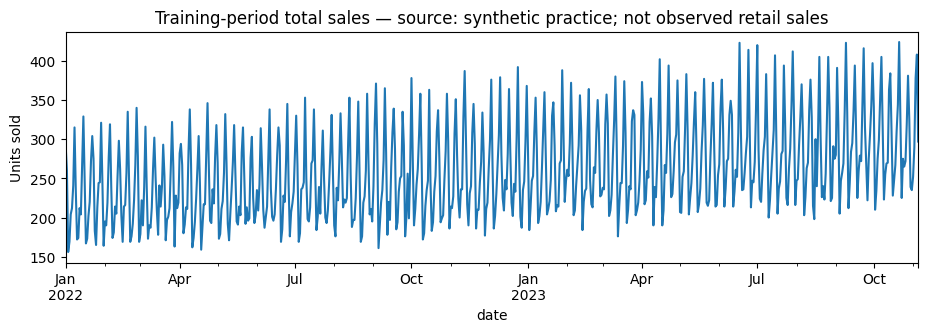

In [4]:
# Keep Week 1 independent of the Week 2 forecasting module.
end = data.date.max()
test_start = end-pd.Timedelta(days=27)
validation_start = test_start-pd.Timedelta(days=28)
windows = {'train_end':validation_start-pd.Timedelta(days=1), 'validation_start':validation_start,
           'validation_end':test_start-pd.Timedelta(days=1), 'test_start':test_start, 'test_end':end}
training = data[data.date <= windows['train_end']].copy()
display(pd.Series({key:str(value) for key,value in windows.items() if not key.endswith('origins')}))
training.groupby('date').sales.sum().plot(figsize=(11,3),title='Training-period total sales — source: '+source['data_kind'],ylabel='Units sold')
plt.show()

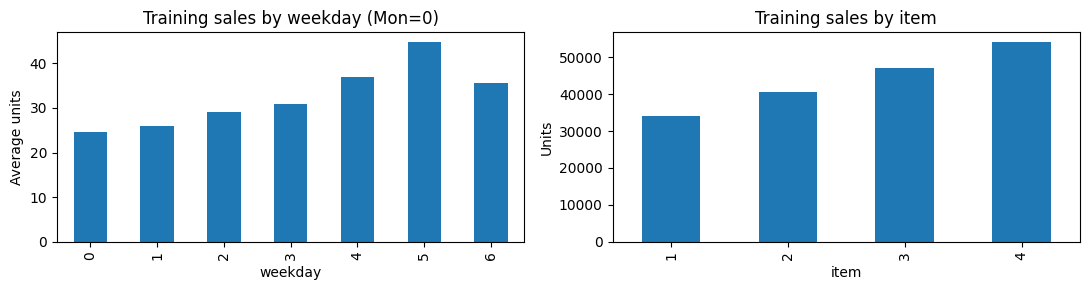

In [5]:
weekday = training.assign(weekday=training.date.dt.dayofweek).groupby('weekday').sales.mean()
fig,axes=plt.subplots(1,2,figsize=(11,3))
weekday.plot.bar(ax=axes[0],title='Training sales by weekday (Mon=0)',ylabel='Average units')
training.groupby('item').sales.sum().plot.bar(ax=axes[1],title='Training sales by item',ylabel='Units')
plt.tight_layout(); plt.show()

## 4. Use statsmodels for a seasonal diagnostic
The PDF lists statsmodels. Additive decomposition separates trend, weekly seasonality and residuals in a training-series example. This two-sided descriptive diagnostic is **not** used to create forecasting features; forecast features remain past-only.

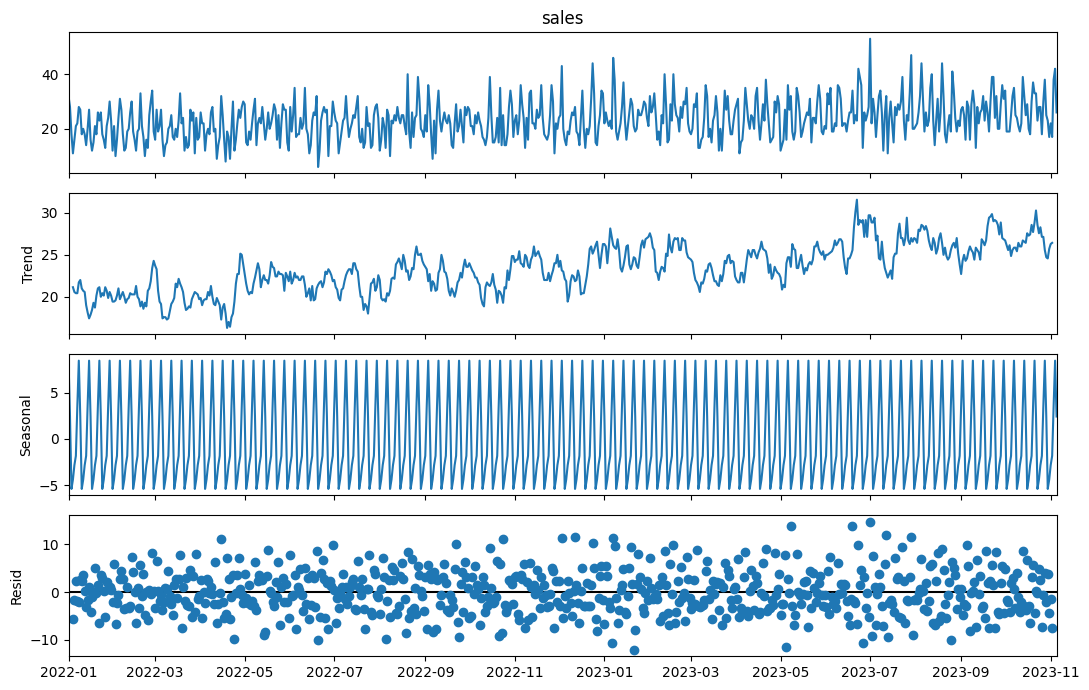

In [6]:
from statsmodels.tsa.seasonal import seasonal_decompose
key = next(iter(training.groupby(['store','item']).groups))
series = training[(training.store==key[0]) & (training.item==key[1])].set_index('date').sales.asfreq('D')
decomposition = seasonal_decompose(series,model='additive',period=7)
figure = decomposition.plot()
figure.set_size_inches(11,7)
plt.tight_layout(); plt.show()

## 5. Check that malformed daily data is rejected, not silently repaired

In [7]:
from src.data import validate_sales
invalid = pd.concat([data,data.iloc[[0]]],ignore_index=True)
try:
    validate_sales(invalid)
except ValueError as error:
    print('Expected validation refusal:',error)
else:
    raise AssertionError('Duplicate daily keys must not pass.')

Expected validation refusal: Duplicate date/store/item observations. Resolve their meaning before aggregating.


## Your Week 1 submission
Commit the notebook, data dictionary, quality findings, source notes and charts. Keep restricted raw datasets out of Git. Explain which observations use synthetic data. Add your own written findings here; do not invent business conclusions.